# Predictive Maintenance Intelligence System
### Exploratory analysis, modelling and evaluation notebook

**Data Science internship project** - Machine learning and Flask

This notebook covers data understanding, EDA, cleaning, feature engineering, preprocessing, training and tuning of four models, evaluation and model selection. The saved model used by the Flask app is produced by `train_model.py`, which repeats the same steps; the last section of this notebook checks that both give identical results.

**Contents:** 1 Business problem · 2 Objectives · 3 Dataset · 4 Loading · 5 Data quality · 6 Target and imbalance · 7 Data leakage investigation · 8 Univariate analysis · 9 Multivariate analysis · 10 Correlation · 11 Feature engineering · 12 Preprocessing and split · 13 Model training and tuning · 14 Evaluation · 15 Explainability · 16 Final model selection · 17 Business interpretation · 18 Conclusions and future work

## 1. Business problem
Unplanned machine downtime stops production and can damage equipment. **Predictive maintenance** uses operating data (temperatures, speed, torque, tool wear) to estimate which machines are likely to fail soon, so inspections can be scheduled *before* a breakdown.

The prediction task is **binary classification**: `Machine failure` = 1 (failure) or 0 (no failure).

Two kinds of error have different costs:
- **False negative (missed failure):** a real failure is not flagged. Costly: downtime, damage, safety risk.
- **False positive (false alarm):** a healthy machine is flagged. Cheaper: an unnecessary inspection.

So the model must be judged on how many failures it catches (recall) *and* how many false alarms it creates (precision), not on accuracy alone.

## 2. Project objectives
1. Understand the data and the failure patterns it contains.
2. Clean the data and engineer features without leaking the answer into the inputs.
3. Train, tune and compare Logistic Regression, Decision Tree, Random Forest and an Artificial Neural Network.
4. Evaluate with confusion matrices, accuracy, precision, recall, F1, ROC-AUC and PR-AUC.
5. Select the final model for the maintenance use case and explain the choice.
6. Save the fitted pipeline for the Flask application.

## 3. Dataset description
**AI4I 2020 Predictive Maintenance Dataset** (provided by the mentor as `ai4i2020.csv`). It is a **synthetic** dataset that mimics real milling-machine data, so conclusions here do not automatically transfer to a real factory.

| Column | Meaning |
|---|---|
| `UDI`, `Product ID` | Row identifier and product identifier |
| `Type` | Product quality variant: L (low), M (medium), H (high) |
| `Air temperature [K]`, `Process temperature [K]` | Temperatures in kelvin |
| `Rotational speed [rpm]` | Spindle speed |
| `Torque [Nm]` | Torque |
| `Tool wear [min]` | Minutes of tool use |
| `Machine failure` | **Target**: 1 if the machine failed |
| `TWF`, `HDF`, `PWF`, `OSF`, `RNF` | Failure *mode* flags: tool wear, heat dissipation, power, overstrain, random |

## 4. Loading and inspecting the data

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import core                      # shared feature engineering / schema
import train_model as tm         # shared model definitions and helpers

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 90, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Project root: c:\Users\usnal\Downloads\predictive-maintenance-system\predictive-maintenance-system


In [2]:
df = pd.read_csv(ROOT / "data" / "ai4i2020.csv")
print("Shape (rows, columns):", df.shape)
print()
print("Columns and data types:")
print(df.dtypes.to_string())
df.head()

Shape (rows, columns): (10000, 14)

Columns and data types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 5. Data quality, missing values and duplicates

In [3]:
print("Missing values per column (total = %d):" % df.isna().sum().sum())
print(df.isna().sum().to_string())
print()
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate UDI values:", df["UDI"].duplicated().sum(), "| duplicate Product ID values:", df["Product ID"].duplicated().sum())
print("Duplicates on the model inputs only:", df.duplicated(subset=core.RAW_FEATURES).sum())
print()
print("Consistency checks")
print("  Process temperature > air temperature in every row:", bool((df["Process temperature [K]"] > df["Air temperature [K]"]).all()))
print("  First letter of Product ID equals Type in every row:", bool((df["Product ID"].str[0] == df["Type"]).all()))
print("  Type values:", sorted(df["Type"].unique()))
print("  Target values:", sorted(df["Machine failure"].unique()))
df[core.RAW_NUMERIC].describe().round(2)

Missing values per column (total = 0):
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0

Fully duplicated rows: 0
Duplicate UDI values: 0 | duplicate Product ID values: 0
Duplicates on the model inputs only: 0

Consistency checks
  Process temperature > air temperature in every row: True
  First letter of Product ID equals Type in every row: True
  Type values: ['H', 'L', 'M']
  Target values: [np.int64(0), np.int64(1)]


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.0,10000.00,10000.00,10000.00,10000.00
mean,300.0,310.01,1538.78,39.99,107.95
std,2.0,1.48,179.28,9.97,63.65
min,295.3,305.70,1168.00,3.80,0.00
25%,298.3,308.80,1423.00,33.20,53.00
50%,300.1,310.10,1503.00,40.10,108.00
75%,301.5,311.10,1612.00,46.80,162.00
max,304.5,313.80,2886.00,76.60,253.00


**What this shows.** The data is clean: no missing values, no duplicated rows, and the values are physically consistent (process temperature is always above air temperature). Nothing needs imputing or removing.

**Cleaning decisions**
- *Missing values / duplicates:* none exist, so nothing is imputed or dropped.
- *Inconsistent data:* none found. `Product ID` starts with the same letter as `Type` in every row, so it adds no information beyond `Type` and is only an identifier.
- *Outliers:* checked in section 8. They are **kept** because they turn out to carry the failure signal.

## 6. Target distribution and class imbalance

Machine failure
No failure    9661
Failure        339
Failure rate: 3.39%  |  imbalance ratio: 1 failure per 28 non-failures
Accuracy of a model that ALWAYS predicts 'no failure': 96.61%


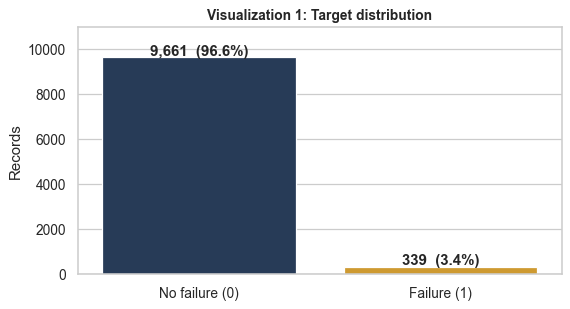

In [4]:
counts = df["Machine failure"].value_counts().sort_index()
rate = df["Machine failure"].mean()
print(counts.rename({0: "No failure", 1: "Failure"}).to_string())
print(f"Failure rate: {rate:.2%}  |  imbalance ratio: 1 failure per {counts[0] / counts[1]:.0f} non-failures")
print(f"Accuracy of a model that ALWAYS predicts 'no failure': {1 - rate:.2%}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.barplot(x=["No failure (0)", "Failure (1)"], y=counts.values, palette=["#1f3a5f", "#e8a317"], ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v + 80, f"{v:,}  ({v / len(df):.1%})", ha="center", fontweight="bold")
ax.set(title="Visualization 1: Target distribution", ylabel="Records"); ax.set_ylim(0, 11000)
plt.tight_layout(); plt.show()

**What it represents.** How many records are failures versus normal operation.

**What the data reveals.** Only 339 of 10,000 records (3.39%) are failures, roughly 1 in 29. A model that always says "no failure" would be 96.61% accurate while catching nothing.

**Why it matters.** The classes are heavily imbalanced, so **accuracy is misleading**. We use recall, precision, F1, PR-AUC and the confusion matrix, give the models class weights where supported, and tune the decision threshold.

## 7. Data leakage investigation
Leakage happens when a model is given information that would not be available at prediction time. The five failure-mode flags (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) are suspicious: they describe *why* a machine failed. We test how closely they track the target.

In [5]:
modes = core.LEAKAGE_COLUMNS
any_mode = (df[modes].sum(axis=1) > 0).astype(int)
print(pd.crosstab(df["Machine failure"], any_mode, rownames=["Machine failure"], colnames=["at least one mode flag"]))
fail = df["Machine failure"] == 1
print()
print(f"Failures that have at least one mode flag: {(any_mode[fail] == 1).sum()} of {fail.sum()}")
print(f"Failures with NO mode flag: {(any_mode[fail] == 0).sum()}")
print(f"Rows with RNF = 1 but no failure: {((df['RNF'] == 1) & ~fail).sum()} of {(df['RNF'] == 1).sum()}")
print("Mode counts:", df[modes].sum().to_dict(), "| failures with 2+ modes:", int((df[modes].sum(axis=1) > 1).sum()))

at least one mode flag     0    1
Machine failure                  
0                       9643   18
1                          9  330

Failures that have at least one mode flag: 330 of 339
Failures with NO mode flag: 9
Rows with RNF = 1 but no failure: 18 of 19
Mode counts: {'TWF': 46, 'HDF': 115, 'PWF': 95, 'OSF': 98, 'RNF': 19} | failures with 2+ modes: 24


**Decision: the five mode columns are excluded from the model inputs.**
- 330 of the 339 failures carry at least one mode flag. The flags are effectively the target spelled out in more detail, so a model using them would look near-perfect.
- They are only known *after* a failure has been diagnosed. A maintenance engineer predicting tomorrow's failures does not have them, and the Flask app asks only for sensor readings.
- `RNF` is a random flag unrelated to the sensors: 18 of its 19 rows are not failures.

`UDI` and `Product ID` are **excluded** as identifiers (and `Product ID` repeats `Type`).

**Inputs used:** `Type`, `Air temperature [K]`, `Process temperature [K]`, `Rotational speed [rpm]`, `Torque [Nm]`, `Tool wear [min]`, plus three engineered features (section 11). **Target:** `Machine failure`.

## 8. Univariate analysis

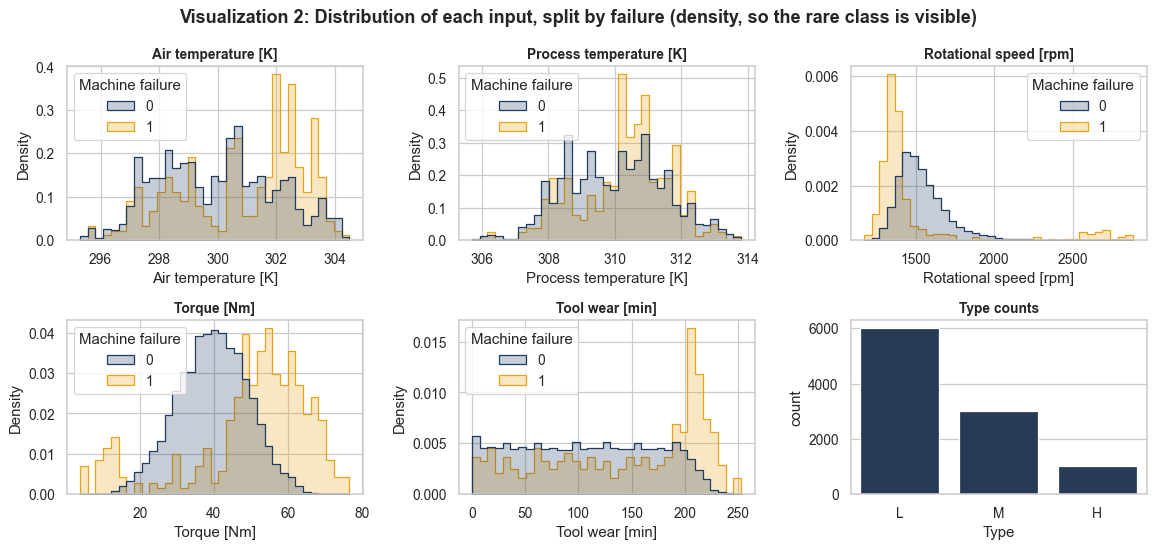

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2))
for ax, col in zip(axes.flat, core.RAW_NUMERIC):
    sns.histplot(data=df, x=col, hue="Machine failure", bins=35, stat="density", common_norm=False,
                 palette={0: "#1f3a5f", 1: "#e8a317"}, element="step", ax=ax)
    ax.set_title(col)
sns.countplot(data=df, x="Type", order=["L", "M", "H"], color="#1f3a5f", ax=axes.flat[5]); axes.flat[5].set_title("Type counts")
fig.suptitle("Visualization 2: Distribution of each input, split by failure (density, so the rare class is visible)", fontweight="bold")
plt.tight_layout(); plt.show()

**What it represents.** The shape of each input, with failed machines (orange) compared with healthy ones (blue). Densities are normalised so the 339 failures are not hidden by the 9,661 healthy rows.

**What the data reveals.** Air and process temperature overlap almost completely between the two groups. Torque is the clearest separator: failures sit in the high tail (mean 50.2 Nm versus 39.6 Nm). Tool wear is higher for failures (mean 143.8 versus 106.7 min), and rotational speed is slightly lower (1,496 versus 1,540 rpm). 60% of machines are type L.

**Why it matters.** Torque, tool wear and speed are the inputs that carry a visible failure signal on their own. Temperatures alone are weak, which suggests combining them (their difference) rather than using them separately.

2026-10-17 16:01:44,307 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-17 16:01:44,334 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-17 16:01:44,411 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-17 16:01:44,431 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-17 16:01:44,505 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If 

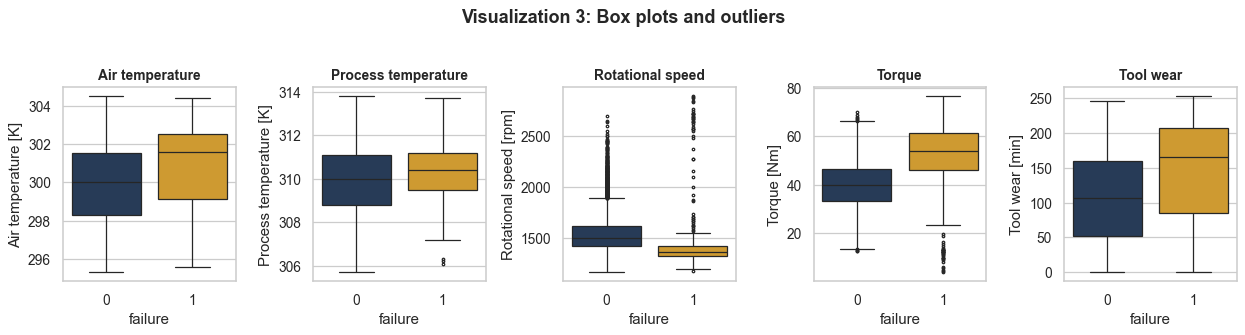

,feature,IQR outliers,failure rate inside outliers
0,Air temperature [K],0,NaN
1,Process temperature [K],0,NaN
2,Rotational speed [rpm],418,0.084
3,Torque [Nm],69,0.899
4,Tool wear [min],0,NaN


In [7]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3.6))
for ax, col in zip(axes, core.RAW_NUMERIC):
    sns.boxplot(data=df, y=col, x="Machine failure", palette=["#1f3a5f", "#e8a317"], ax=ax, fliersize=2)
    ax.set_title(col.split(" [")[0]); ax.set_xlabel("failure")
fig.suptitle("Visualization 3: Box plots and outliers", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

rows = []
for col in core.RAW_NUMERIC:
    q1, q3 = df[col].quantile([.25, .75]); iqr = q3 - q1
    mask = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    rows.append({"feature": col, "IQR outliers": int(mask.sum()),
                 "failure rate inside outliers": df.loc[mask, "Machine failure"].mean() if mask.any() else np.nan})
pd.DataFrame(rows).round(3)

**What it represents.** Box plots show the median, spread and unusually extreme values (outliers, by the 1.5 x IQR rule).

**What the data reveals.** Air temperature, process temperature and tool wear have no IQR outliers. Rotational speed has 418 high-speed outliers, only 8.4% of which fail. Torque has 69 outliers and **89.9% of them are failures**, compared with 3.39% overall.

**Why it matters.** The outliers are not data errors. They are real extreme operating conditions, and the extreme torque readings are exactly where machines fail. **Removing outliers would delete the signal we want to learn**, so they are kept.

## 9. Multivariate analysis: temperature, speed, torque, tool wear and failures

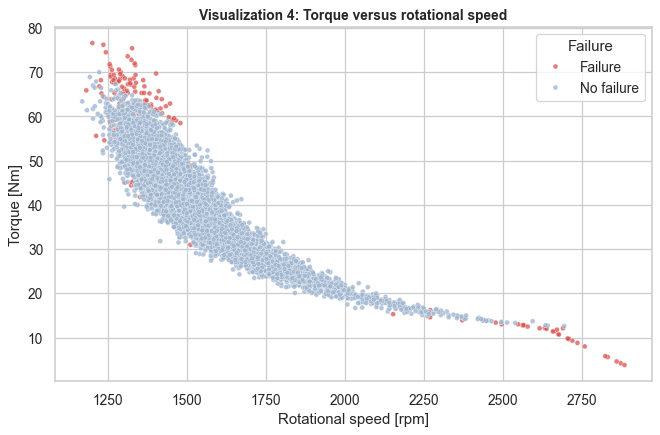

Correlation between speed and torque: -0.875


In [8]:
d = df.assign(Failure=df["Machine failure"].map({0: "No failure", 1: "Failure"}))
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.scatterplot(data=d.sort_values("Failure"), x="Rotational speed [rpm]", y="Torque [Nm]", hue="Failure",
                palette={"No failure": "#9db4cf", "Failure": "#d9534f"}, s=16, alpha=.75, ax=ax)
ax.set_title("Visualization 4: Torque versus rotational speed")
plt.tight_layout(); plt.show()
print("Correlation between speed and torque: %.3f" % df["Rotational speed [rpm]"].corr(df["Torque [Nm]"]))

**What it represents.** Every machine plotted by speed and torque; red points are failures.

**What the data reveals.** Speed and torque are strongly negatively correlated (-0.875): faster machines run at lower torque. Failures form two clusters away from the main cloud: **high torque / low speed** and **very low torque / high speed**.

**Why it matters.** Failure depends on the *combination* of speed and torque, which is mechanical power (torque x angular speed). This motivates the engineered `power_W` feature and explains why non-linear models should do better than a linear one.

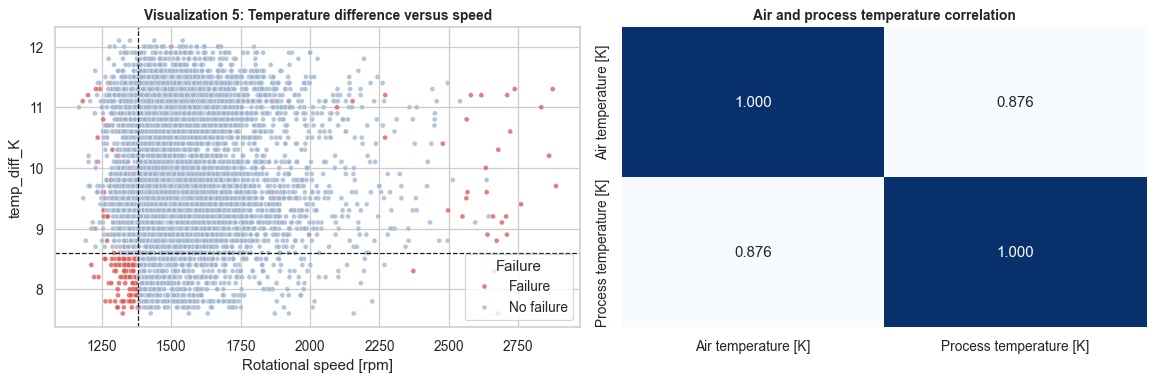

Rows with temperature difference < 8.6 K AND speed < 1380 rpm: 115  ->  failure rate 100.0%
Failure rate everywhere else: 2.27%


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
df["temp_diff_K"] = df["Process temperature [K]"] - df["Air temperature [K]"]
sns.scatterplot(data=d.assign(temp_diff_K=df["temp_diff_K"]).sort_values("Failure"), x="Rotational speed [rpm]", y="temp_diff_K",
                hue="Failure", palette={"No failure": "#9db4cf", "Failure": "#d9534f"}, s=16, alpha=.75, ax=axes[0])
axes[0].axhline(8.6, color="k", ls="--", lw=1); axes[0].axvline(1380, color="k", ls="--", lw=1)
axes[0].set_title("Visualization 5: Temperature difference versus speed")
region = (df["temp_diff_K"] < 8.6) & (df["Rotational speed [rpm]"] < 1380)
sns.heatmap(df[["Air temperature [K]", "Process temperature [K]"]].corr(), annot=True, fmt=".3f", cmap="Blues", ax=axes[1], cbar=False)
axes[1].set_title("Air and process temperature correlation")
plt.tight_layout(); plt.show()
print(f"Rows with temperature difference < 8.6 K AND speed < 1380 rpm: {region.sum()}  ->  failure rate {df.loc[region, 'Machine failure'].mean():.1%}")
print(f"Failure rate everywhere else: {df.loc[~region, 'Machine failure'].mean():.2%}")

**What it represents.** Left: the gap between process and air temperature against speed. Right: how strongly the two temperatures move together.

**What the data reveals.** Air and process temperature are almost the same signal (correlation 0.876), so each alone says little. Their **difference** is informative: all 115 records with a temperature difference below 8.6 K *and* speed below 1,380 rpm are failures (100%), against 2.3% elsewhere. This is a heat-dissipation problem: a small temperature gap at low speed means the machine cannot shed heat.

**Why it matters.** It confirms that a derived feature (`temp_diff_K`) is more useful than the raw temperatures and that failures follow interacting conditions, not single thresholds. The 8.6 K and 1,380 rpm lines come from the dataset's documented failure rules and are shown only to illustrate what the data contains. The model learns its own boundaries.

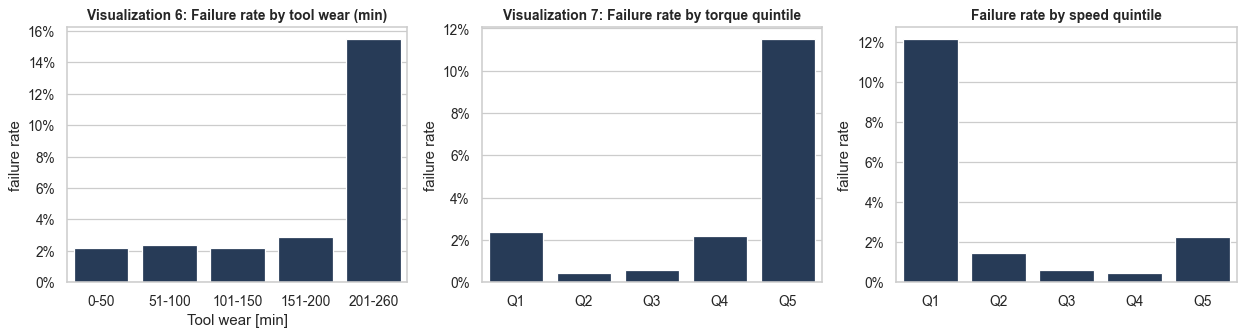

,count,failures,failure_rate
Tool wear [min],,,
0-50,2396,52,0.0217
51-100,2271,53,0.0233
101-150,2295,50,0.0218
151-200,2276,66,0.0290
201-260,762,118,0.1549


In [10]:
bins = pd.cut(df["Tool wear [min]"], [-1, 50, 100, 150, 200, 260], labels=["0-50", "51-100", "101-150", "151-200", "201-260"])
g = df.groupby(bins, observed=True)["Machine failure"].agg(["count", "sum", "mean"]).rename(columns={"sum": "failures", "mean": "failure_rate"})
tq = df.groupby(pd.qcut(df["Torque [Nm]"], 5), observed=True)["Machine failure"].mean()
rp = df.groupby(pd.qcut(df["Rotational speed [rpm]"], 5), observed=True)["Machine failure"].mean()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
sns.barplot(x=g.index.astype(str), y=g["failure_rate"], color="#1f3a5f", ax=axes[0]); axes[0].set_title("Visualization 6: Failure rate by tool wear (min)")
sns.barplot(x=[f"Q{i+1}" for i in range(5)], y=tq.values, color="#1f3a5f", ax=axes[1]); axes[1].set_title("Visualization 7: Failure rate by torque quintile")
sns.barplot(x=[f"Q{i+1}" for i in range(5)], y=rp.values, color="#1f3a5f", ax=axes[2]); axes[2].set_title("Failure rate by speed quintile")
for ax in axes: ax.set_ylabel("failure rate"); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()
g.round(4)

**What it represents.** The failure rate inside bands of tool wear, and inside quintiles (five equal-sized groups) of torque and speed. Q1 is the lowest group, Q5 the highest.

**What the data reveals.**
- *Tool wear:* the rate is flat at about 2.2-2.9% up to 200 minutes, then jumps to **15.5% above 200 minutes**. This is a threshold effect, not a smooth trend.
- *Torque:* the pattern is **U-shaped**: 2.3% in the lowest quintile, only 0.4% and 0.6% in the next two, then 2.2% and **11.5% in the highest quintile**.
- *Speed:* the lowest-speed quintile fails at 12.2%; the rest are between 0.5% and 2.3%.

**Why it matters.** Because the effects are thresholds and U-shapes, a straight-line model cannot capture them, while trees and neural networks can. It also tells maintenance planners that tools used beyond roughly 200 minutes need attention.

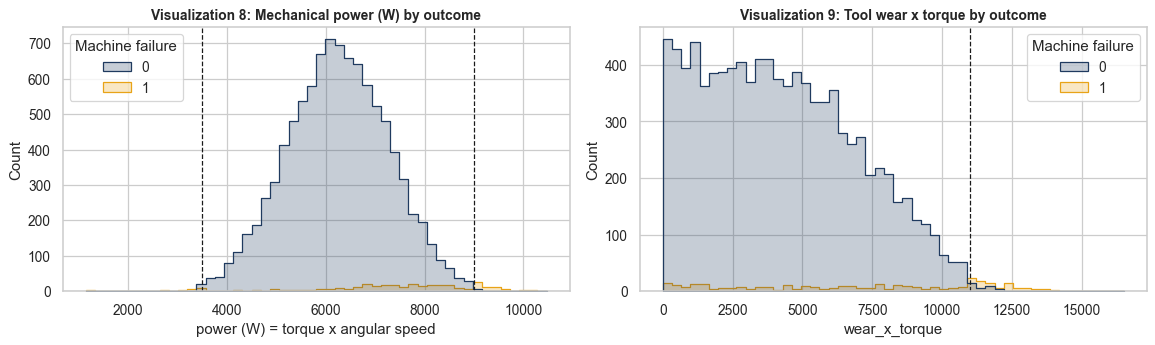

Power outside 3,500-9,000 W: 95 rows, failure rate 100.0%; inside the band: 2.46%
Wear x torque above 11,000: 125 rows, failure rate 81.6%


In [11]:
f = core.add_features(df[core.RAW_FEATURES])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(x=f["power_W"], hue=df["Machine failure"], bins=50, palette={0: "#1f3a5f", 1: "#e8a317"}, element="step", ax=axes[0])
axes[0].axvline(3500, color="k", ls="--", lw=1); axes[0].axvline(9000, color="k", ls="--", lw=1)
axes[0].set_title("Visualization 8: Mechanical power (W) by outcome"); axes[0].set_xlabel("power (W) = torque x angular speed")
sns.histplot(x=f["wear_x_torque"], hue=df["Machine failure"], bins=50, palette={0: "#1f3a5f", 1: "#e8a317"}, element="step", ax=axes[1])
axes[1].axvline(11000, color="k", ls="--", lw=1); axes[1].set_title("Visualization 9: Tool wear x torque by outcome")
plt.tight_layout(); plt.show()
out = (f["power_W"] < 3500) | (f["power_W"] > 9000)
print(f"Power outside 3,500-9,000 W: {out.sum()} rows, failure rate {df.loc[out, 'Machine failure'].mean():.1%}; inside the band: {df.loc[~out, 'Machine failure'].mean():.2%}")
hi = f["wear_x_torque"] > 11000
print(f"Wear x torque above 11,000: {hi.sum()} rows, failure rate {df.loc[hi, 'Machine failure'].mean():.1%}")

**What it represents.** Two engineered quantities: mechanical power (torque x angular speed) and the product of tool wear and torque (an overstrain indicator), split by outcome.

**What the data reveals.** All 95 records with power below 3,500 W or above 9,000 W failed (100%), versus 2.46% inside that band. Records with wear x torque above 11,000 fail 81.6% of the time (125 rows).

**Why it matters.** These two features turn the speed-torque and wear-torque interactions into single numbers that models can use directly. They are built only from inputs available at prediction time, so they do not leak the target. The dashed lines are dataset-documented limits, drawn for illustration.

## 10. Correlation analysis

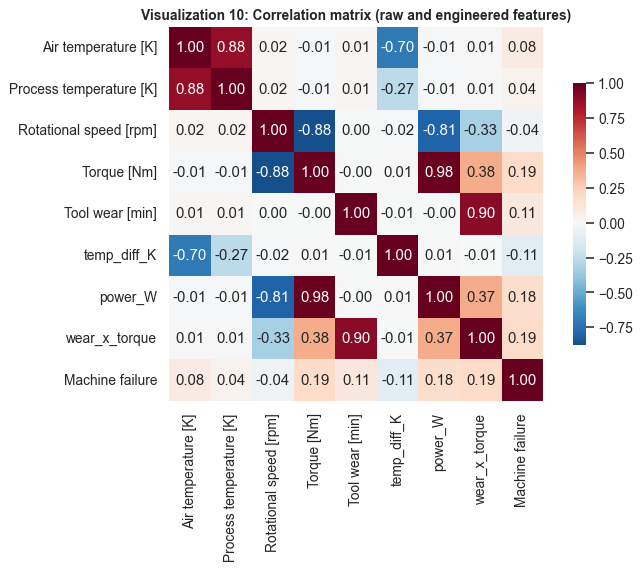

Torque [Nm]                0.191
wear_x_torque              0.190
power_W                    0.176
temp_diff_K               -0.112
Tool wear [min]            0.105
Air temperature [K]        0.083
Rotational speed [rpm]    -0.044
Process temperature [K]    0.036
Name: Machine failure, dtype: float64

In [12]:
fe = core.add_features(df[core.RAW_FEATURES]).assign(**{"Machine failure": df["Machine failure"]})
corr = fe[core.NUMERIC_MODEL + ["Machine failure"]].corr()
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Visualization 10: Correlation matrix (raw and engineered features)")
plt.tight_layout(); plt.show()
corr["Machine failure"].drop("Machine failure").sort_values(key=abs, ascending=False).round(3)

**What it represents.** Pearson (straight-line) correlation between every pair of numeric features and the target.

**What the data reveals.** Linear correlations with failure are all weak: torque 0.19, wear x torque 0.19, power 0.18, temperature difference -0.11, tool wear 0.10. Air and process temperature correlate 0.88 with each other, and speed and torque -0.88.

**Why it matters.** Weak linear correlations do not mean weak predictability. The strong effects are thresholds and interactions (sections 8 and 9), which correlation cannot see. This is a warning that Logistic Regression may struggle. The high correlation between inputs (multicollinearity) is a second reason to use derived features such as the temperature difference.

## 11. Feature engineering
Three physically motivated features are derived from the raw inputs (defined once in `core.add_features`, so training and the web app cannot disagree):

| Feature | Formula | Why |
|---|---|---|
| `temp_diff_K` | process temp - air temp | Heat dissipation; removes the near-duplicate temperature signal |
| `power_W` | torque x rpm x 2π / 60 | Mechanical power; captures the speed-torque interaction |
| `wear_x_torque` | tool wear x torque | Overstrain: a worn tool under high torque |

Categorical `Type` is one-hot encoded and numeric features are standardised **inside the model pipeline**, so they are fitted on training data only.

In [13]:
fe = core.add_features(df[core.RAW_FEATURES])
print(fe[core.ENGINEERED].describe().round(1))
print()
print("Mean of each engineered feature by outcome:")
print(fe[core.ENGINEERED].groupby(df["Machine failure"]).mean().round(1))

       temp_diff_K  power_W  wear_x_torque
count      10000.0  10000.0        10000.0
mean          10.0   6279.7         4314.7
std            1.0   1067.4         2826.6
min            7.6   1148.4            0.0
25%            9.3   5561.2         1963.6
50%            9.8   6271.0         4013.0
75%           11.0   7003.0         6279.0
max           12.1  10469.9        16497.0

Mean of each engineered feature by outcome:
                 temp_diff_K  power_W  wear_x_torque
Machine failure                                     
0                       10.0   6244.5         4213.8
1                        9.4   7282.8         7187.9


## 12. Preprocessing and train-test split

In [14]:
X, y = df[core.RAW_FEATURES], df["Machine failure"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=tm.TEST_SIZE, stratify=y, random_state=tm.SEED)
print(f"Train: {X_train.shape}, failures {y_train.sum()} ({y_train.mean():.2%})")
print(f"Test : {X_test.shape}, failures {y_test.sum()} ({y_test.mean():.2%})")
print()
print("Preprocessing + model pipeline (nothing is fitted until .fit(X_train, y_train)):")
tm.build_pipeline(tm.model_spaces()["Logistic Regression"][0])

Train: (8000, 6), failures 271 (3.39%)
Test : (2000, 6), failures 68 (3.40%)

Preprocessing + model pipeline (nothing is fitted until .fit(X_train, y_train)):


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...002C05F94DF80>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass 

- **Stratified 80/20 split** keeps the same 3.39% failure rate in both parts, so the 68 test failures are representative.
- The test set is used **once**, at the end, for reporting. All tuning and the choice of model use only the training set (5-fold cross-validation).
- The scaler and encoder live **inside** the pipeline, so in every cross-validation fold they learn from that fold's training part only. This prevents preprocessing leakage.

## 13. Model training and hyper-parameter tuning
Each model is tuned with `GridSearchCV` (5-fold stratified, scored by **PR-AUC**, which suits rare events). Imbalance handling:
- Logistic Regression, Decision Tree, Random Forest: `class_weight` so the rare failures count more.
- ANN (`MLPClassifier`) has no class-weight option, so it relies on threshold tuning.
- **Decision threshold:** for every model, the threshold is chosen on out-of-fold training predictions to maximise **F2**, which weights recall four times as much as precision. The 4:1 weighting is an assumption that a missed failure costs more than a false alarm.

This step takes about two minutes on one CPU core.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=tm.SEED)
results, fitted, oof_probs = [], {}, {}
for name, (est, grid) in tm.model_spaces().items():
    gs = GridSearchCV(tm.build_pipeline(est), grid, scoring="average_precision", cv=cv, n_jobs=1).fit(X_train, y_train)
    oof = cross_val_predict(tm.build_pipeline(est).set_params(**gs.best_params_), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    thr = tm.best_threshold(y_train, oof)
    prob = gs.best_estimator_.predict_proba(X_test)[:, 1]
    results.append({"model": name, "best_params": gs.best_params_, "cv_pr_auc": gs.best_score_, "threshold": thr,
                    "cv_f2": tm.metrics_at(y_train, oof, thr)["f2"], "prob_test": prob})
    fitted[name], oof_probs[name] = gs.best_estimator_, oof
    print(f"{name:20s} CV PR-AUC {gs.best_score_:.3f} | tuned threshold {thr:.3f} | best params {gs.best_params_}")

Logistic Regression  CV PR-AUC 0.486 | tuned threshold 0.775 | best params {'clf__C': 0.1}
Decision Tree        CV PR-AUC 0.835 | tuned threshold 0.950 | best params {'clf__max_depth': 6, 'clf__min_samples_leaf': 5}
Random Forest        CV PR-AUC 0.893 | tuned threshold 0.345 | best params {'clf__max_depth': 10, 'clf__min_samples_leaf': 1}
ANN (MLP)            CV PR-AUC 0.727 | tuned threshold 0.228 | best params {'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (64, 32), 'clf__learning_rate_init': 0.01}


## 14. Model evaluation and comparison

In [16]:
rows = []
for r in results:
    m = tm.metrics_at(y_test, r["prob_test"], r["threshold"]); cm = m["confusion_matrix"]
    rows.append({"model": r["model"], "cv_pr_auc": r["cv_pr_auc"], "threshold": r["threshold"], "accuracy": m["accuracy"],
                 "precision": m["precision"], "recall": m["recall"], "f1": m["f1"], "f2": m["f2"],
                 "roc_auc": roc_auc_score(y_test, r["prob_test"]), "pr_auc": average_precision_score(y_test, r["prob_test"]),
                 "missed failures (FN)": cm["fn"], "false alarms (FP)": cm["fp"]})
comparison = pd.DataFrame(rows).set_index("model").round(4)
print("Test-set results at each model's tuned threshold")
comparison

Test-set results at each model's tuned threshold


,cv_pr_auc,threshold,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,missed failures (FN),false alarms (FP)
model,,,,,,,,,,,
Logistic Regression,0.4859,0.7751,0.9500,0.3571,0.5882,0.4444,0.5208,0.9310,0.4400,28,72
Decision Tree,0.8347,0.9500,0.9915,0.9180,0.8235,0.8682,0.8408,0.9259,0.8631,12,5
Random Forest,0.8933,0.3450,0.9840,0.7195,0.8676,0.7867,0.8333,0.9867,0.8795,9,23
ANN (MLP),0.7269,0.2276,0.9755,0.6067,0.7941,0.6879,0.7479,0.9788,0.7670,14,35


In [17]:
default_rows = []
for r in results:
    m = tm.metrics_at(y_test, r["prob_test"], 0.5); cm = m["confusion_matrix"]
    default_rows.append({"model": r["model"], "accuracy": m["accuracy"], "precision": m["precision"], "recall": m["recall"],
                         "f1": m["f1"], "missed failures (FN)": cm["fn"], "false alarms (FP)": cm["fp"]})
print("For comparison: the same models at the default 0.5 threshold")
pd.DataFrame(default_rows).set_index("model").round(4)

For comparison: the same models at the default 0.5 threshold


,accuracy,precision,recall,f1,missed failures (FN),false alarms (FP)
model,,,,,,
Logistic Regression,0.8495,0.1700,0.8824,0.2850,8,293
Decision Tree,0.9530,0.4122,0.8971,0.5648,7,87
Random Forest,0.9915,0.9636,0.7794,0.8618,15,2
ANN (MLP),0.9790,0.7708,0.5441,0.6379,31,11


**Reading the comparison.**
- **Logistic Regression** is clearly the weakest: recall 0.59 and precision 0.36, with 28 missed failures and 72 false alarms. Its accuracy (95.0%) is *below* the 96.6% of the "always no failure" baseline, a direct sign that the failure patterns are not linear.
- **Decision Tree** has the highest precision (0.92) and the highest test F2 (0.841) with 12 missed failures and only 5 false alarms. Its threshold is very high (0.95), which suggests its probabilities come from a few leaves and are coarse.
- **Random Forest** has the best ranking ability (ROC-AUC 0.987, PR-AUC 0.880) and the best recall (0.868): it misses 9 failures, with 23 false alarms.
- **ANN (MLP)** lands in between (recall 0.79, precision 0.61, 14 missed, 35 false alarms) and is the hardest to interpret.

With only 68 failures in the test set, one or two failures change recall by 1.5-3 points, so the Decision Tree and Random Forest results are **close** and should not be treated as an exact ranking.

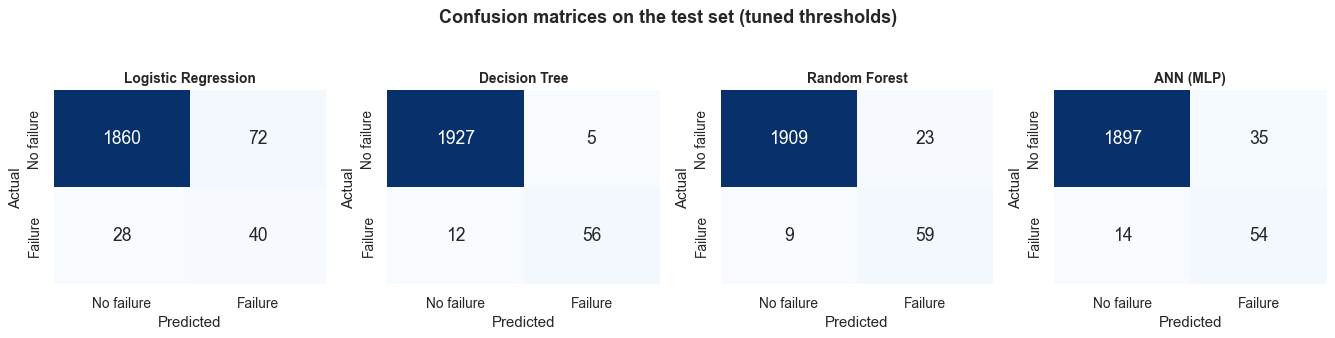

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, r in zip(axes, results):
    cm = tm.metrics_at(y_test, r["prob_test"], r["threshold"])["confusion_matrix"]
    mat = np.array([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]])
    sns.heatmap(mat, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 14},
                xticklabels=["No failure", "Failure"], yticklabels=["No failure", "Failure"])
    ax.set_title(r["model"]); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
fig.suptitle("Confusion matrices on the test set (tuned thresholds)", fontweight="bold", y=1.04)
plt.tight_layout(); plt.show()

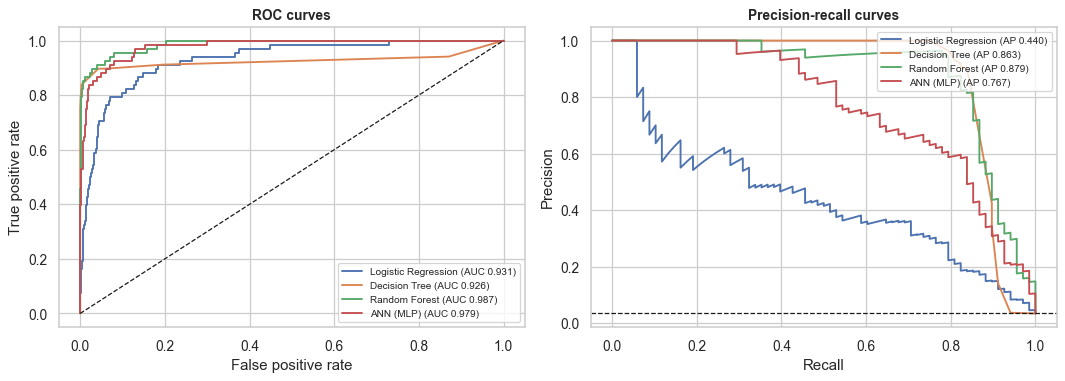

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for r in results:
    fpr, tpr, _ = roc_curve(y_test, r["prob_test"]); axes[0].plot(fpr, tpr, label=f"{r['model']} (AUC {roc_auc_score(y_test, r['prob_test']):.3f})")
    p, rc, _ = precision_recall_curve(y_test, r["prob_test"]); axes[1].plot(rc, p, label=f"{r['model']} (AP {average_precision_score(y_test, r['prob_test']):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1); axes[1].set(title="Precision-recall curves", xlabel="Recall", ylabel="Precision")
for ax in axes: ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=8)
plt.tight_layout(); plt.show()

**What the curves show.** The ROC curve plots catch-rate against false-alarm rate; the precision-recall curve shows how precision falls as we demand more recall. ROC-AUC can look flattering when failures are rare (the Logistic Regression ROC-AUC is 0.93 despite poor recall), so the **PR curve is the more honest view**. Random Forest and the Decision Tree stay highest for longest, and Logistic Regression drops fastest.

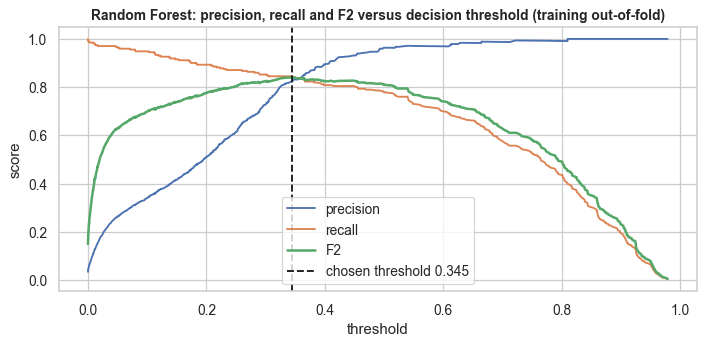

In [20]:
final_name = "Random Forest"
oof = oof_probs[final_name]
prec, rec, thr = precision_recall_curve(y_train, oof)
f2 = 5 * prec[:-1] * rec[:-1] / np.maximum(4 * prec[:-1] + rec[:-1], 1e-12)
chosen_thr = [r for r in results if r["model"] == final_name][0]["threshold"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thr, prec[:-1], label="precision"); ax.plot(thr, rec[:-1], label="recall"); ax.plot(thr, f2, label="F2", lw=2)
ax.axvline(chosen_thr, color="k", ls="--", label=f"chosen threshold {chosen_thr:.3f}")
ax.set(title=f"{final_name}: precision, recall and F2 versus decision threshold (training out-of-fold)", xlabel="threshold", ylabel="score")
ax.legend(); plt.tight_layout(); plt.show()

**The trade-off in one picture.** Lowering the threshold catches more failures (recall rises) but raises more false alarms (precision falls). The dashed line is the point that maximises F2 on the training data. A maintenance team that finds false alarms very cheap could choose a lower threshold; one with scarce inspection capacity could choose a higher one.

## 15. Feature importance and explainability

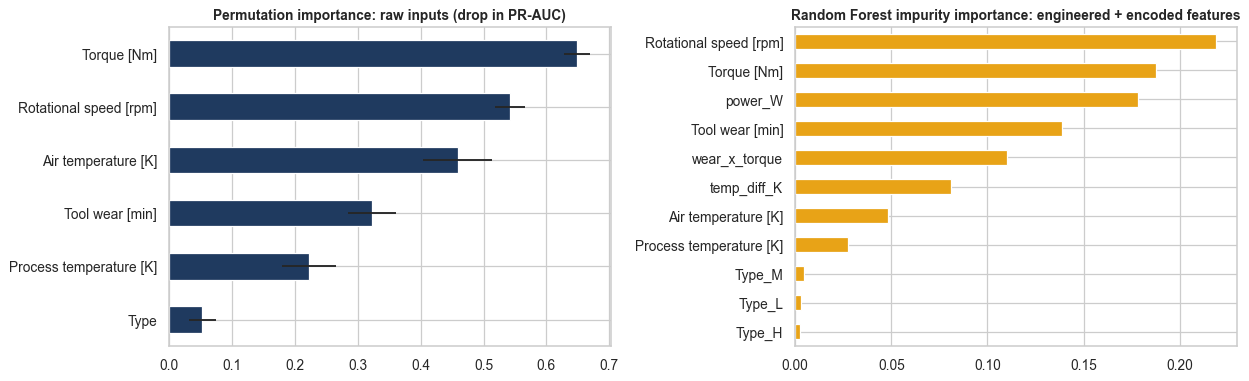

Rotational speed [rpm]     0.219
Torque [Nm]                0.188
power_W                    0.178
Tool wear [min]            0.139
wear_x_torque              0.110
temp_diff_K                0.081
Air temperature [K]        0.048
Process temperature [K]    0.027
Type_M                     0.005
Type_L                     0.003
Type_H                     0.002


In [21]:
final = fitted[final_name]
imp = permutation_importance(final, X_test, y_test, scoring="average_precision", n_repeats=10, random_state=tm.SEED, n_jobs=1)
raw_imp = pd.Series(imp.importances_mean, index=core.RAW_FEATURES).sort_values()
pre, clf = final[:-1], final[-1]
names = list(pre[-1].get_feature_names_out())
gini = pd.Series(clf.feature_importances_, index=names).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
raw_imp.plot.barh(ax=axes[0], color="#1f3a5f", xerr=pd.Series(imp.importances_std, index=core.RAW_FEATURES)[raw_imp.index]); axes[0].set_title("Permutation importance: raw inputs (drop in PR-AUC)")
gini.plot.barh(ax=axes[1], color="#e8a317"); axes[1].set_title("Random Forest impurity importance: engineered + encoded features")
plt.tight_layout(); plt.show()
print(gini.sort_values(ascending=False).round(3).to_string())

**What it shows.** Left: how much the test PR-AUC drops when one raw input is shuffled. Right: how much the forest's splits rely on each engineered or encoded feature.

**What the data reveals.** Torque and rotational speed are the most important raw inputs, followed by air temperature, tool wear and process temperature. Product type matters little. In the engineered view, the most used features are rotational speed, the temperature difference, wear x torque and power. The raw temperatures matter mostly *through* their difference, which is why shuffling air temperature hurts even though it correlates weakly with failure.

**Why it matters.** The model relies on the same physical drivers seen in the EDA: speed-torque (power), heat dissipation and tool overstrain. That is reassuring for trust and gives maintenance teams concrete variables to watch. Importance shows what the model uses, not what causes failure, and correlated features share importance.

## 16. Final model selection

In [22]:
summary = pd.DataFrame([{"model": r["model"], "cv_f2_at_tuned_threshold": r["cv_f2"], "cv_pr_auc": r["cv_pr_auc"]} for r in results]).set_index("model").round(4)
chosen = max(results, key=lambda r: (r["cv_f2"], r["cv_pr_auc"]))["model"]
print("Selection uses TRAINING cross-validation only (the test set is not used to choose).")
print("Selected model:", chosen)
summary

Selection uses TRAINING cross-validation only (the test set is not used to choose).
Selected model: Random Forest


,cv_f2_at_tuned_threshold,cv_pr_auc
model,,
Logistic Regression,0.5297,0.4859
Decision Tree,0.8069,0.8347
Random Forest,0.8413,0.8933
ANN (MLP),0.6951,0.7269


In [23]:
saved = joblib.load(ROOT / "models" / "predictive_maintenance_model.joblib")
table = pd.read_csv(ROOT / "outputs" / "model_comparison.csv").set_index("model")
same_metrics = np.allclose(table.loc[comparison.index, ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]].values,
                           comparison[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]].values, atol=1e-3)
print("Saved model in the Flask app:", saved["model_name"], "| threshold", round(saved["threshold"], 4))
print("Matches model selected in this notebook:", saved["model_name"] == chosen)
print("Metrics identical to train_model.py outputs:", bool(same_metrics))

Saved model in the Flask app: Random Forest | threshold 0.345
Matches model selected in this notebook: True
Metrics identical to train_model.py outputs: True


**Selected model: Random Forest.** Reasons:
1. It has the best cross-validated F2 on the training data, the metric that reflects the business priority of catching failures.
2. It has the strongest ranking quality (test ROC-AUC 0.987 and PR-AUC 0.880) and the highest recall (0.868, 59 of 68 failures caught).
3. It outputs smoother, more usable probabilities than a single tree, which the app turns into risk categories.

**Honest caveats.**
- The Decision Tree is a close competitor with fewer false alarms (5 versus 23) and is far easier to explain. On this small test set the two are statistically hard to separate. If false alarms were expensive or explainability mattered most, the Decision Tree would be a legitimate choice.
- The ANN did not beat the tree-based models here, and the dataset is small for neural networks.
- Accuracy was never the selection criterion: all four models exceed or approach the 96.6% baseline, which says little.

## 17. Business interpretation
- **Missed failures vs false alarms.** At the chosen threshold the Random Forest misses 9 of 68 failures and raises 23 false alarms among 1,932 healthy machines. In other words, roughly 87% of real failures are flagged in advance, at the price of about 1 unnecessary inspection per 2.6 correct alerts (precision 0.72). Whether that trade is acceptable depends on actual downtime and inspection costs, which this project does not have.
- **Where to act.** Tool wear beyond about 200 minutes, very high torque, very low speed, small temperature gaps and out-of-band mechanical power are the situations in which failures concentrate.
- **How the app uses the model.** The same fitted pipeline scores single machines and CSV batches, and the probability is mapped to Low / Medium / High with a project-defined rule (High: at or above the threshold; Medium: at or above half of it). This rule is a convenience, **not** an industry safety standard.

## 18. Conclusions and future improvements
**Conclusions**
- The data is clean but heavily imbalanced (3.39% failures), so accuracy is not a valid yardstick.
- The five failure-mode flags and the identifiers were excluded to prevent leakage.
- Failures follow thresholds and interactions (tool wear above 200 min, torque and speed extremes, low temperature difference), which is why engineered features and non-linear models outperform Logistic Regression.
- Random Forest was selected by cross-validated F2; it catches about 87% of failures on the held-out test set.

**Limitations**
- Synthetic data whose failure rules are largely deterministic; real-world performance will be lower and noisier.
- Only 339 failures overall (68 in the test set), so metrics carry real uncertainty.
- No cost data, so the F2 weighting is an assumption.

**Future work**
- Validate on real machine logs and add time-series features (trends, rolling statistics).
- Estimate real downtime and inspection costs and choose the threshold by expected cost.
- Calibrate the probabilities and report confidence intervals (for example by repeated cross-validation).
- Add SHAP-style explanations for each individual prediction.
- Monitor for data drift and retrain on a schedule once deployed.